# Resultados Fase 1: Clasificación Diagnóstica

Comparación: DenseNet121 vs ViT-B/16 vs LLaVA-Med vs Mini-VLM

Métricas: Accuracy, AUC-ROC, F1-Score, Sensibilidad, Especificidad

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

# --- Configuración ---
RESULTS_DIR = Path("../outputs/results")
MODELS = ["densenet", "vit", "llava_med", "mini_vlm"]
MODEL_LABELS = {
    "densenet": "DenseNet121",
    "vit": "ViT-B/16",
    "llava_med": "LLaVA-Med",
    "mini_vlm": "Mini-VLM",
}
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]  # uno por modelo

# Descripciones completas de las 7 clases HAM10000
# Fuente: Tschandl et al. 2018 (doi:10.7910/DVN/DBW86T)
HAM10000_CLASS_DESCRIPTIONS = {
    "MEL":   "Melanoma",
    "NV":    "Melanocytic Nevus",
    "BCC":   "Basal Cell Carcinoma",
    "AKIEC": "Actinic Keratosis / Intraep. Carcinoma",
    "BKL":   "Benign Keratosis-like",
    "DF":    "Dermatofibroma",
    "VASC":  "Vascular Lesion",
}


## 1. Carga de resultados

In [15]:
def load_model_results(model: str) -> dict | None:
    """Carga métricas y predicciones de un modelo. Retorna None si no existen."""
    results_path = RESULTS_DIR / f"{model}_test_results.json"
    preds_path = RESULTS_DIR / f"{model}_predictions.json"
    if not results_path.exists():
        return None
    with open(results_path) as f:
        metrics = json.load(f)
    data = {"metrics": metrics, "predictions": None, "class_names": None}
    if preds_path.exists():
        with open(preds_path) as f:
            preds = json.load(f)
        data["predictions"] = preds
        data["class_names"] = preds.get("class_names")
    return data


# Cargar todos los modelos disponibles
all_results = {}
for model in MODELS:
    r = load_model_results(model)
    if r is not None:
        all_results[model] = r
        print(f"✓ {MODEL_LABELS[model]} cargado")
    else:
        print(f"  {MODEL_LABELS[model]} — sin resultados todavía")

available = list(all_results.keys())
print(f"\nModelos disponibles: {[MODEL_LABELS[m] for m in available]}")

# Tomar class_names del primer modelo disponible con predicciones
class_names = None
for m in available:
    if all_results[m]["class_names"]:
        class_names = all_results[m]["class_names"]
        break

# Etiquetas completas: "Descripción (ACRÓNIMO)" para usar en ejes de gráficos
class_labels_full = [
    f"{HAM10000_CLASS_DESCRIPTIONS.get(c.upper(), c)} ({c})"
    for c in class_names
] if class_names else None

print(f"\nClases ({len(class_names)}):")
for acr, full in zip(class_names, class_labels_full):
    print(f"  {acr:6s} → {HAM10000_CLASS_DESCRIPTIONS.get(acr.upper(), acr)}")


✓ DenseNet121 cargado
✓ ViT-B/16 cargado
  LLaVA-Med — sin resultados todavía
  Mini-VLM — sin resultados todavía

Modelos disponibles: ['DenseNet121', 'ViT-B/16']

Clases (7):
  MEL    → Melanoma
  NV     → Melanocytic Nevus
  BCC    → Basal Cell Carcinoma
  AKIEC  → Actinic Keratosis / Intraep. Carcinoma
  BKL    → Benign Keratosis-like
  DF     → Dermatofibroma
  VASC   → Vascular Lesion


## 2. Tabla comparativa de métricas

In [16]:
rows = []
for model in available:
    m = all_results[model]["metrics"]
    # Calcular AUC macro desde y_prob si está disponible (auc_roc_macro puede ser null)
    auc_macro = m.get("auc_roc_macro")
    if auc_macro is None and all_results[model]["predictions"] is not None:
        p = all_results[model]["predictions"]
        y_true_arr = np.array(p["y_true"])
        y_prob_arr = np.array(p["y_prob"])
        n_cls = y_prob_arr.shape[1]
        y_bin = label_binarize(y_true_arr, classes=list(range(n_cls)))
        aucs = []
        for i in range(n_cls):
            if y_bin[:, i].sum() > 0:
                fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob_arr[:, i])
                aucs.append(auc(fpr, tpr))
        auc_macro = float(np.mean(aucs)) if aucs else None

    rows.append({
        "Modelo": MODEL_LABELS[model],
        "Accuracy": m.get("accuracy"),
        "F1 (weighted)": m.get("f1_weighted"),
        "AUC-ROC (macro)": auc_macro,
        "Sensibilidad (macro)": m.get("sensitivity_macro"),
        "Especificidad (macro)": m.get("specificity_macro"),
    })

df_summary = pd.DataFrame(rows).set_index("Modelo")

def highlight_max(s):
    is_max = s == s.max()
    return ["font-weight: bold; background-color: #d4edda" if v else "" for v in is_max]

df_summary.style \
    .format("{:.4f}", na_rep="—") \
    .apply(highlight_max) \
    .set_caption("Tabla 1. Comparación de métricas en test set (HAM10000)")


,Accuracy,F1 (weighted),AUC-ROC (macro),Sensibilidad (macro),Especificidad (macro)
Modelo,,,,,
DenseNet121,0.5230,0.5805,0.8219,0.3942,0.9198
ViT-B/16,0.6314,0.6676,0.8923,0.5196,0.9326


## 3. Matrices de confusión

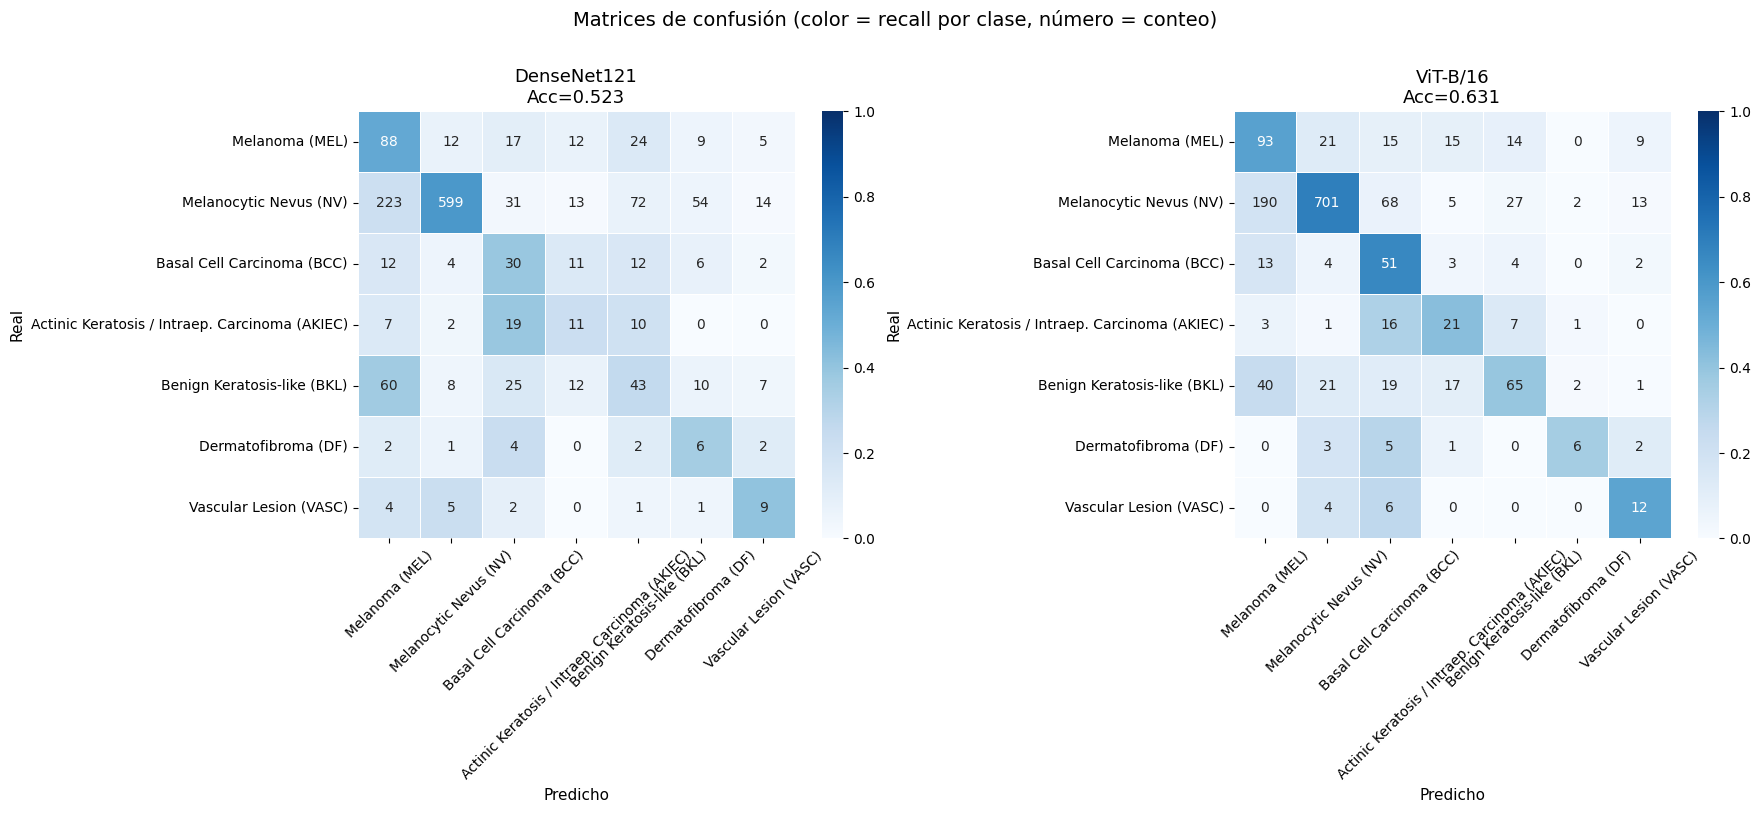

In [17]:
n = len(available)
cols = min(n, 2)
rows_grid = (n + 1) // 2
fig, axes = plt.subplots(rows_grid, cols, figsize=(9 * cols, 8 * rows_grid))
axes = np.array(axes).reshape(-1) if n > 1 else [axes]

for ax, model in zip(axes, available):
    cm = np.array(all_results[model]["metrics"]["confusion_matrix"])
    # Normalizar por fila para ver tasas de recall por clase
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    labels = class_labels_full if class_labels_full else [str(i) for i in range(cm.shape[0])]
    sns.heatmap(
        cm_norm, annot=cm, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels,
        vmin=0, vmax=1, ax=ax, linewidths=0.5,
    )
    ax.set_title(f"{MODEL_LABELS[model]}\nAcc={all_results[model]['metrics']['accuracy']:.3f}", fontsize=13)
    ax.set_xlabel("Predicho", fontsize=11)
    ax.set_ylabel("Real", fontsize=11)
    ax.tick_params(axis="x", rotation=45)

# Ocultar ejes sobrantes si n es impar
for ax in axes[n:]:
    ax.set_visible(False)

plt.suptitle("Matrices de confusión (color = recall por clase, número = conteo)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()


## 4. Sensibilidad y especificidad por clase

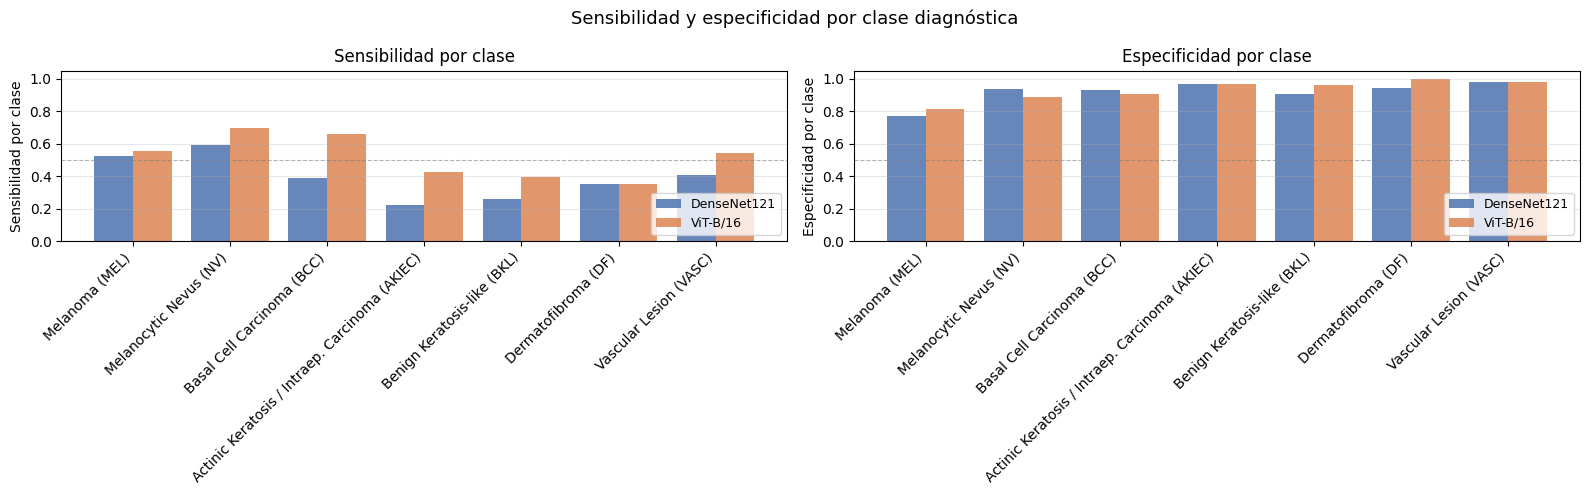

In [18]:
labels = class_labels_full if class_labels_full else [str(i) for i in range(7)]
n_cls = len(labels)
x = np.arange(n_cls)
n_models = len(available)
bar_w = 0.8 / n_models  # ancho total = 0.8, dividido entre modelos

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=False)

for metric_idx, (metric_key, title, ax) in enumerate([
    ("sensitivity_per_class", "Sensibilidad por clase", axes[0]),
    ("specificity_per_class", "Especificidad por clase", axes[1]),
]):
    for i, model in enumerate(available):
        values = all_results[model]["metrics"].get(metric_key, [])
        offset = (i - n_models / 2 + 0.5) * bar_w
        color = PALETTE[MODELS.index(model) % len(PALETTE)]
        ax.bar(x + offset, values, width=bar_w, label=MODEL_LABELS[model], color=color, alpha=0.85)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(title)
    ax.set_title(title, fontsize=12)
    ax.legend(loc="lower right", fontsize=9)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8, alpha=0.6)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Sensibilidad y especificidad por clase diagnóstica", fontsize=13)
plt.tight_layout()
plt.show()


## 5. Curvas ROC por modelo

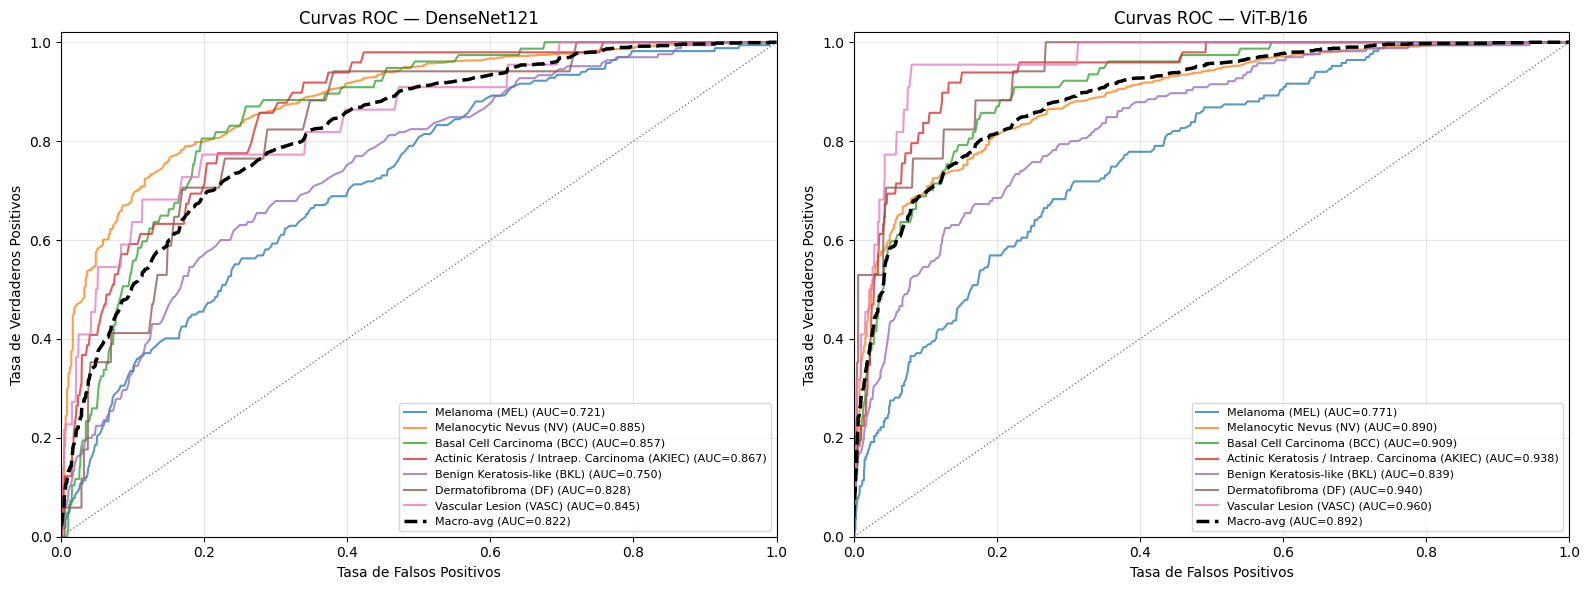

In [19]:
models_with_probs = [m for m in available if all_results[m]["predictions"] is not None]
if not models_with_probs:
    print("Sin y_prob disponible. Ejecutar train_classifier.py primero.")
else:
    cls_labels = class_labels_full if class_labels_full else [str(i) for i in range(7)]
    n_cls = len(cls_labels)
    n_m = len(models_with_probs)
    fig, axes = plt.subplots(1, n_m, figsize=(8 * n_m, 6))
    if n_m == 1:
        axes = [axes]

    for ax, model in zip(axes, models_with_probs):
        p = all_results[model]["predictions"]
        y_true_arr = np.array(p["y_true"])
        y_prob_arr = np.array(p["y_prob"])
        y_bin = label_binarize(y_true_arr, classes=list(range(n_cls)))

        cls_aucs = []
        for i in range(n_cls):
            if y_bin[:, i].sum() == 0:
                continue
            fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob_arr[:, i])
            cls_auc = auc(fpr, tpr)
            cls_aucs.append(cls_auc)
            ax.plot(fpr, tpr, lw=1.5, alpha=0.75, label=f"{cls_labels[i]} (AUC={cls_auc:.3f})")

        # Macro-average
        all_fpr = np.unique(np.concatenate([
            roc_curve(y_bin[:, i], y_prob_arr[:, i])[0]
            for i in range(n_cls) if y_bin[:, i].sum() > 0
        ]))
        mean_tpr = np.zeros_like(all_fpr)
        for i in range(n_cls):
            if y_bin[:, i].sum() == 0:
                continue
            fpr_i, tpr_i, _ = roc_curve(y_bin[:, i], y_prob_arr[:, i])
            mean_tpr += np.interp(all_fpr, fpr_i, tpr_i)
        mean_tpr /= sum(1 for i in range(n_cls) if y_bin[:, i].sum() > 0)
        macro_auc = auc(all_fpr, mean_tpr)
        ax.plot(all_fpr, mean_tpr, "k--", lw=2.5, label=f"Macro-avg (AUC={macro_auc:.3f})")

        ax.plot([0, 1], [0, 1], "gray", linestyle=":", lw=1)
        ax.set_xlim([0, 1])
        ax.set_ylim([0, 1.02])
        ax.set_xlabel("Tasa de Falsos Positivos")
        ax.set_ylabel("Tasa de Verdaderos Positivos")
        ax.set_title(f"Curvas ROC — {MODEL_LABELS[model]}", fontsize=12)
        ax.legend(loc="lower right", fontsize=8)
        ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


## 6. Análisis de errores


DenseNet121 — Top 10 confusiones más frecuentes
                                          Real                    Predicho  Cantidad
                        Melanocytic Nevus (NV)              Melanoma (MEL)       223
                        Melanocytic Nevus (NV) Benign Keratosis-like (BKL)        72
                   Benign Keratosis-like (BKL)              Melanoma (MEL)        60
                        Melanocytic Nevus (NV)         Dermatofibroma (DF)        54
                        Melanocytic Nevus (NV)  Basal Cell Carcinoma (BCC)        31
                   Benign Keratosis-like (BKL)  Basal Cell Carcinoma (BCC)        25
                                Melanoma (MEL) Benign Keratosis-like (BKL)        24
Actinic Keratosis / Intraep. Carcinoma (AKIEC)  Basal Cell Carcinoma (BCC)        19
                                Melanoma (MEL)  Basal Cell Carcinoma (BCC)        17
                        Melanocytic Nevus (NV)      Vascular Lesion (VASC)        14


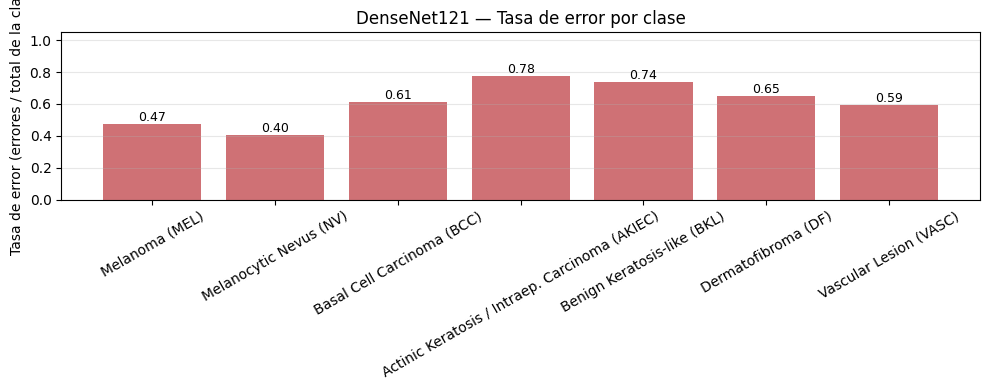


ViT-B/16 — Top 10 confusiones más frecuentes
                                          Real                                       Predicho  Cantidad
                        Melanocytic Nevus (NV)                                 Melanoma (MEL)       190
                        Melanocytic Nevus (NV)                     Basal Cell Carcinoma (BCC)        68
                   Benign Keratosis-like (BKL)                                 Melanoma (MEL)        40
                        Melanocytic Nevus (NV)                    Benign Keratosis-like (BKL)        27
                   Benign Keratosis-like (BKL)                         Melanocytic Nevus (NV)        21
                                Melanoma (MEL)                         Melanocytic Nevus (NV)        21
                   Benign Keratosis-like (BKL)                     Basal Cell Carcinoma (BCC)        19
                   Benign Keratosis-like (BKL) Actinic Keratosis / Intraep. Carcinoma (AKIEC)        17
Actinic Keratosis 

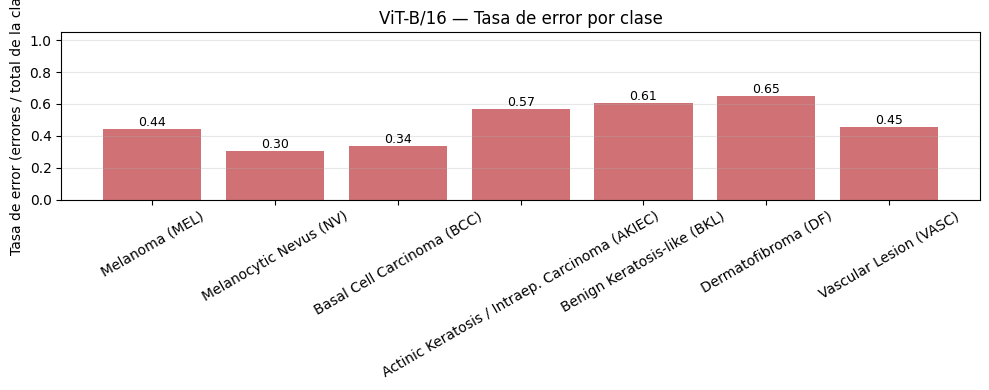

In [20]:
models_with_preds = [m for m in available if all_results[m]["predictions"] is not None]
cls_labels = class_labels_full if class_labels_full else [str(i) for i in range(7)]

for model in models_with_preds:
    p = all_results[model]["predictions"]
    y_true_arr = np.array(p["y_true"])
    y_pred_arr = np.array(p["y_pred"])
    errors_mask = y_true_arr != y_pred_arr

    # Top confusiones
    pairs = list(zip(y_true_arr[errors_mask], y_pred_arr[errors_mask]))
    from collections import Counter
    top_errors = Counter(pairs).most_common(10)
    df_errors = pd.DataFrame(
        [(cls_labels[t], cls_labels[pr], cnt) for (t, pr), cnt in top_errors],
        columns=["Real", "Predicho", "Cantidad"],
    )
    print(f"\n{'='*50}")
    print(f"{MODEL_LABELS[model]} — Top 10 confusiones más frecuentes")
    print(f"{'='*50}")
    print(df_errors.to_string(index=False))

    # Errores totales por clase verdadera
    total_per_class = np.bincount(y_true_arr, minlength=len(cls_labels))
    errors_per_class = np.bincount(y_true_arr[errors_mask], minlength=len(cls_labels))
    error_rate = np.where(total_per_class > 0, errors_per_class / total_per_class, 0)

    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.bar(cls_labels, error_rate, color="#C44E52", alpha=0.8)
    ax.bar_label(bars, fmt="%.2f", fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Tasa de error (errores / total de la clase)")
    ax.set_title(f"{MODEL_LABELS[model]} — Tasa de error por clase")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
